# Program 01: a basic classifier

**What:** train a ResNet-18 on all 10 classes of CIFAR-10 and report test accuracy.

**Why:** every later program is this same loop plus extra loss terms. If this loop is clean, everything after it is easier.

**Understanding note:** a model is a function whose weights are shaped by the loss. Changing the loss is how you control what the model learns, and later, what it forgets.

**Done when:** test accuracy is about 85% or higher, and reloading the saved model gives the same number.

Run the cells from top to bottom (or *Run All*). The full 30 epochs take a while on a laptop GPU; set `EPOCHS = 1` below for a quick check first.

## 1. Setup
Import the libraries and our shared code from `common/`.

In [1]:
import sys
from pathlib import Path

# Find the project root (the folder that holds common/), whether this notebook
# was opened from the project root or from programs/.
ROOT = Path.cwd() if (Path.cwd() / "common").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))  # lets us import common/

import time

import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from common.data import get_cifar10_loaders
from common.models import resnet18_cifar
from common.utils import RESULTS_DIR, get_device, log_run, set_seed

## 2. Settings

All the numbers you might want to change live here.

- **lr** (learning rate): how big each weight update is.
- **weight decay**: gently pulls weights toward 0, which reduces overfitting.
- **seed**: fixes all randomness so a run can be repeated exactly.

In [2]:
EPOCHS = 30         # use 1 for a quick test run
LR = 0.1
BATCH_SIZE = 128
WEIGHT_DECAY = 5e-4
SEED = 0
WORKERS = 4

set_seed(SEED)
device = get_device()
print("Device:", device)

Device: cuda


## 3. Data

CIFAR-10: 50,000 training and 10,000 test images, 32×32 pixels, 10 classes.
Training images get random crops and horizontal flips (augmentation), so the model sees slightly different versions each epoch. Test images are left unchanged.

In [3]:
train_loader, test_loader = get_cifar10_loaders(BATCH_SIZE, WORKERS)
classes = train_loader.dataset.classes
print("train images:", len(train_loader.dataset), "  test images:", len(test_loader.dataset))
print("classes:", classes)

train images: 50000   test images: 10000
classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


Look at a few training images (after augmentation). Colors look odd because the images are normalized; we undo that for display.

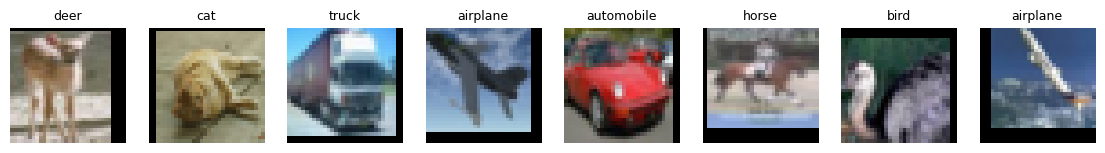

In [4]:
from common.data import CIFAR10_MEAN, CIFAR10_STD

images, labels = next(iter(train_loader))
mean, std = torch.tensor(CIFAR10_MEAN).view(3, 1, 1), torch.tensor(CIFAR10_STD).view(3, 1, 1)
fig, axes = plt.subplots(1, 8, figsize=(14, 2.2))
for ax, img, y in zip(axes, images, labels):
    ax.imshow((img * std + mean).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(classes[y], fontsize=9)
    ax.axis("off")
plt.show()

## 4. Model

ResNet-18, changed for small images. The ImageNet version starts with a 7×7 stride-2 conv plus a max-pool, which shrinks a 32×32 image to 8×8 before the first block. We use a 3×3 stride-1 conv and remove the max-pool instead (see `common/models.py`).

In [5]:
model = resnet18_cifar(num_classes=10).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"ResNet-18 has {n_params/1e6:.1f} million weights")

ResNet-18 has 11.2 million weights


## 5. One epoch of training

One pass over all training images. For each batch:

1. **forward:** run the images through the model to get scores (logits) for each class;
2. **loss:** cross-entropy measures how wrong those scores are;
3. **backward + step:** compute the gradients and update the weights to reduce the loss.

Mixed precision (`autocast` + `GradScaler`) runs parts of the model in float16. It is about 2× faster on this GPU and does not change what the model learns.

In [6]:
def train_one_epoch(model, loader, optimizer, scaler, device):
    """One pass over the training data. Returns (average loss, training accuracy)."""
    model.train()  # turns on training behavior of BatchNorm
    loss_fn = nn.CrossEntropyLoss()
    total_loss, correct, seen = 0.0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)

        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            logits = model(images)
            loss = loss_fn(logits, labels)

        # The three steps of learning: clear old gradients, compute new ones, update weights.
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        seen += labels.size(0)

    return total_loss / seen, correct / seen

## 6. Evaluation

Measure accuracy without changing any weights. `model.eval()` makes BatchNorm use its stored statistics, and `torch.no_grad()` skips gradient bookkeeping, which saves time and memory.

In [7]:
@torch.no_grad()
def evaluate(model, loader, device):
    """Accuracy of the model on a loader, as a fraction between 0 and 1."""
    model.eval()
    correct, seen = 0, 0
    for images, labels in loader:
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        logits = model(images)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        seen += labels.size(0)
    return correct / seen

## 7. Optimizer and learning-rate schedule

- **SGD with momentum 0.9:** each update keeps part of the previous direction, which smooths out noisy batches.
- **Cosine schedule:** start at lr 0.1 and smoothly lower it to about 0 by the last epoch. Big steps early to make progress, small steps late to settle into a good solution.

In [8]:
optimizer = torch.optim.SGD(model.parameters(), lr=LR, momentum=0.9, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.amp.GradScaler(enabled=device.type == "cuda")

## 8. Train
This is the long cell. Each line printed is one epoch.

In [9]:
history = {"train_loss": [], "train_acc": [], "test_acc": []}
start = time.time()
for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, scaler, device)
    test_acc = evaluate(model, test_loader, device)
    scheduler.step()

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["test_acc"].append(test_acc)
    print(f"epoch {epoch:2d}/{EPOCHS}  loss {train_loss:.3f}  "
          f"train {train_acc*100:5.2f}%  test {test_acc*100:5.2f}%  ({time.time() - start:.0f}s)")

epoch  1/30  loss 2.132  train 23.14%  test 37.60%  (44s)
epoch  2/30  loss 1.486  train 45.21%  test 54.50%  (73s)
epoch  3/30  loss 1.184  train 57.17%  test 58.91%  (101s)
epoch  4/30  loss 0.959  train 65.91%  test 67.16%  (130s)
epoch  5/30  loss 0.801  train 72.10%  test 74.38%  (158s)
epoch  6/30  loss 0.678  train 76.55%  test 74.99%  (186s)
epoch  7/30  loss 0.596  train 79.27%  test 69.91%  (215s)
epoch  8/30  loss 0.550  train 81.10%  test 79.68%  (243s)
epoch  9/30  loss 0.507  train 82.73%  test 78.07%  (271s)
epoch 10/30  loss 0.473  train 83.65%  test 81.94%  (300s)
epoch 11/30  loss 0.439  train 84.90%  test 83.70%  (328s)
epoch 12/30  loss 0.414  train 85.85%  test 82.01%  (356s)
epoch 13/30  loss 0.387  train 86.67%  test 82.67%  (385s)
epoch 14/30  loss 0.360  train 87.62%  test 83.87%  (413s)
epoch 15/30  loss 0.336  train 88.56%  test 83.98%  (441s)
epoch 16/30  loss 0.307  train 89.53%  test 86.78%  (470s)
epoch 17/30  loss 0.287  train 90.13%  test 82.93%  (498s)

## 9. Learning curves

The loss should fall and both accuracies should rise. A big gap between train and test accuracy means the model is memorizing the training images (overfitting).

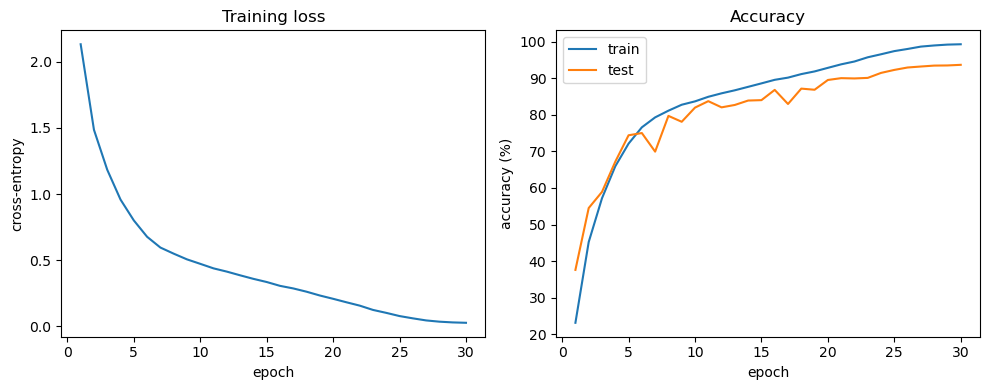

In [10]:
epochs = range(1, len(history["train_loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(epochs, history["train_loss"])
ax1.set(title="Training loss", xlabel="epoch", ylabel="cross-entropy")
ax2.plot(epochs, [a * 100 for a in history["train_acc"]], label="train")
ax2.plot(epochs, [a * 100 for a in history["test_acc"]], label="test")
ax2.set(title="Accuracy", xlabel="epoch", ylabel="accuracy (%)")
ax2.legend()
fig.tight_layout()
RESULTS_DIR.mkdir(exist_ok=True)
fig.savefig(RESULTS_DIR / "01_curves.png", dpi=120)
plt.show()

## 10. Save, reload, check

We save only the weights (`state_dict`), the standard portable way. Then we build a fresh model, load the weights and test again. The two numbers must be the same.

In [11]:
model_path = RESULTS_DIR / "01_resnet18_cifar10.pt"
torch.save(model.state_dict(), model_path)

reloaded = resnet18_cifar(num_classes=10).to(device)
reloaded.load_state_dict(torch.load(model_path, map_location=device))
reloaded_acc = evaluate(reloaded, test_loader, device)

print(f"Final test accuracy:    {test_acc*100:.2f}%")
print(f"Reloaded test accuracy: {reloaded_acc*100:.2f}%  "
      f"({'same' if abs(reloaded_acc - test_acc) < 1e-9 else 'DIFFERENT, check this'})")
print(f"Done when test accuracy >= 85%: {'YES' if test_acc >= 0.85 else 'not yet'}")

Final test accuracy:    93.63%
Reloaded test accuracy: 93.63%  (same)
Done when test accuracy >= 85%: YES


## 11. Log the run
Adds one line (settings + results) to `results/runs.jsonl` (roadmap rule 2).

In [12]:
log_run("01_train_basic",
        {"epochs": EPOCHS, "lr": LR, "batch_size": BATCH_SIZE,
         "weight_decay": WEIGHT_DECAY, "seed": SEED},
        {"test_acc": test_acc, "reloaded_acc": reloaded_acc,
         "minutes": round((time.time() - start) / 60, 1)})

## Lab notebook

*Write one paragraph here: what you saw, and what surprised you.*